# 2. Usines et stations : premier regard

**Étape 2 sur 5.** Ce notebook croise usines et stations.

Variables produites : `stations["nb_usines_5km"]`, `usines_ds_rayon`, `usines_station`, `nappes_usines`, `evolution_lisse`.


In [9]:
%%capture
#Étapes précédentes : exécutées sans afficher leurs figures ni leurs messages, et une seule fois par noyau
#(si les données ne sont pas encore en cache, exécuter d'abord eau_01_donnees.ipynb seul pour suivre le téléchargement)
AFFICHER = globals().get("AFFICHER", True)   #True si ce notebook est ouvert seul, False s'il est appelé par un autre notebook
_afficher_etape_02, AFFICHER = AFFICHER, False
if "ETAPE_01" not in globals():
    %run ./donnees.ipynb
AFFICHER = _afficher_etape_02
plt.close("all")

## 2.1 Répartition des usines et des stations hydrologiques dans les départements étudiés

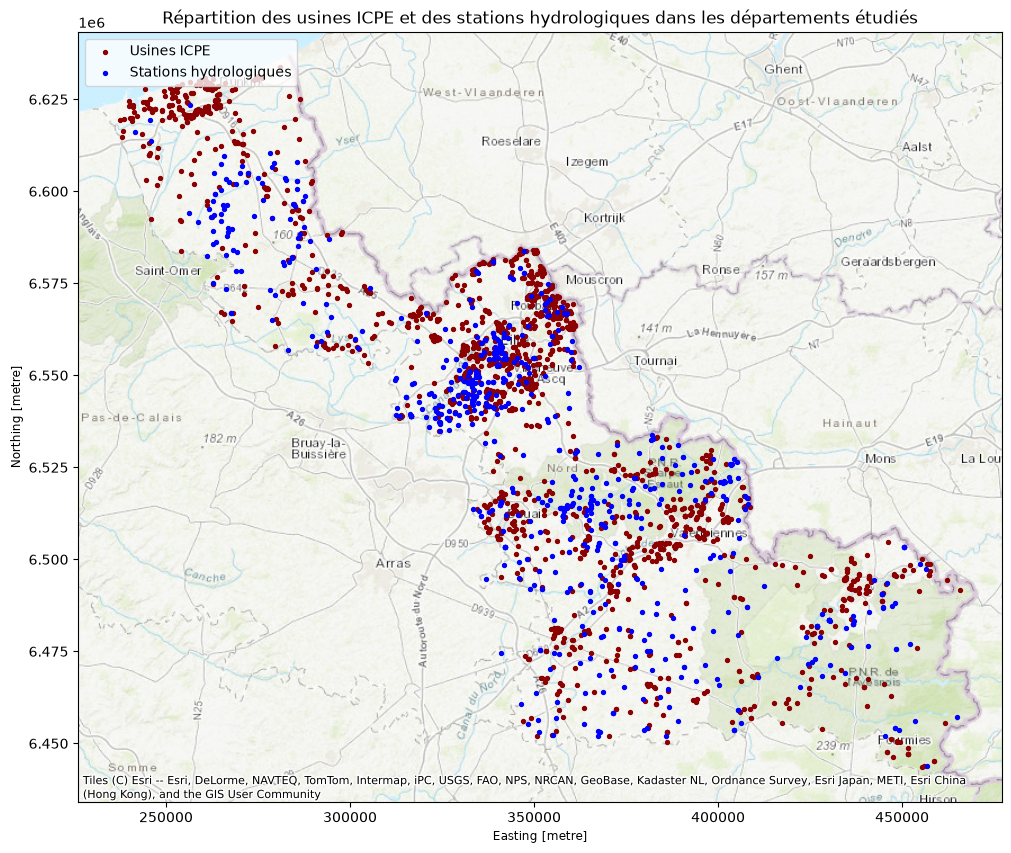

In [10]:
def fig_carte_usines_stations():
    """Carte des usines ICPE (rouge) et des stations de mesure des nappes (bleu)."""
    ax = plt.subplots(figsize=(12, 10))[1]
    installations_indust.to_crs(epsg=3857).plot(ax=ax, color="darkred", markersize=8, label="Usines ICPE", zorder=1)
    stations.to_crs(epsg=3857).plot(ax=ax, color="blue", markersize=8, label="Stations hydrologiques", zorder=2)
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
    plt.legend(loc="upper left")
    plt.title("Répartition des usines ICPE et des stations hydrologiques dans les départements étudiés")
    plt.show()

if AFFICHER:
    fig_carte_usines_stations()

## 2.2 Nombre d'usines autour de chaque station

In [ ]:
#On veut le nombre d'usines qui sont dans les 5km de chaque station
r = 5 * 1000

stations_rayon = stations.copy()
stations_rayon['geometry'] = stations_rayon.geometry.buffer(r)  #On suppose que la station prend toute la place dans un rayon de 5km autour du point où elle est réellement

usines_ds_rayon = gpd.sjoin(installations_indust, stations_rayon, how="inner", predicate="within")
nb_usine_ds_rayon = usines_ds_rayon.groupby('code_bss').size().reset_index(name='nb_usines_5km')

#Si la cellule a déjà tourné dans ce noyau, on retire les anciennes colonnes (nb_usines_5km, et _x/_y s'il y en a) avant de recalculer
stations = stations.drop(columns=[c for c in stations.columns if c.startswith("nb_usines_5km")])
stations = stations.merge(nb_usine_ds_rayon, on='code_bss', how='left')
stations['nb_usines_5km'] = stations['nb_usines_5km'].fillna(0).astype(int) #On remplace les valeurs nulles par 0

KeyError: 'nb_usines_5km'

## 2.3 On relie chaque usine à sa station la plus proche

In [ ]:
#On associe chaque usine à la station la plus proche (si elle est à moins de 5km)
usines_station = gpd.sjoin_nearest(installations_indust, stations[['code_bss', 'geometry']], how="left", max_distance=r, distance_col="distance_station")
usines_station = usines_station.drop_duplicates(subset='code_aiot')  #Plusieurs stations peuvent être au même endroit, on n'en garde qu'une
usines_station = usines_station.drop(columns='index_right')
print(usines_station['code_bss'].notnull().sum(), "usines sur ", usines_station.shape[0], "ont une station à moins de 5km.")

1578 usines sur  1633 ont une station à moins de 5km.


## 2.4 On relie chaque nappe aux usines qui sont à moins de 5 km d'une de ses stations

In [ ]:
#Une station peut mesurer plusieurs nappes : on fait une ligne par couple (usine, nappe)
usines_nappes = usines_ds_rayon[['code_aiot', 'nom_ets', 'codes_masse_eau_edl', 'noms_masse_eau_edl']].explode(['codes_masse_eau_edl', 'noms_masse_eau_edl'])
usines_nappes = usines_nappes.rename(columns={'codes_masse_eau_edl': 'code_nappe', 'noms_masse_eau_edl': 'nom_nappe'})
usines_nappes = usines_nappes.dropna(subset=['code_nappe'])  #On enlève les stations sans nappe
usines_nappes = usines_nappes.drop_duplicates(subset=['code_nappe', 'code_aiot'])  #Une usine proche de 2 stations d'une même nappe ne compte qu'une fois

#Pour chaque nappe, la liste des usines à moins de 5km d'une de ses stations
nappes_usines = usines_nappes.groupby(['code_nappe', 'nom_nappe']).agg(nb_usines=('code_aiot', 'size'), usines=('nom_ets', list)).reset_index()
nappes_usines = nappes_usines.sort_values('nb_usines', ascending=False)
print("On a ", nappes_usines.shape[0], "nappes reliées à au moins une usine.")
nappes_usines

On a  11 nappes reliées à au moins une usine.


,code_nappe,nom_nappe,nb_usines,usines
7,AG315,Calcaire carbonifère de Roubaix-Tourcoing,587,"[Ports de Lille (bat 2 et 4), INTEREP, DALKIA ..."
6,AG314,Sables du Landénien des Flandres,578,"[Société de la Raffinerie de Dunkerque, TIM, L..."
0,AG303,Craie de la vallée de la Deûle,514,"[Ports de Lille (bat 2 et 4), THORNHILL Servic..."
2,AG306,Craie des vallées de la Scarpe et de la Sensée,402,"[GOSSELIN DURIEZ SARL, HANOT Jean-Marc, EPC - ..."
4,AG310,Craie du Cambrésis,230,"[GOSSELIN DURIEZ SARL, TRITUBE, LE COMPTOIR DE..."
3,AG307,Craie du Valenciennois,192,"[HANOT Jean-Marc, NORZINCO, SUEZ RV NORD EST, ..."
8,AG318,Sables du Landénien d'Orchies,188,"[HANOT Jean-Marc, EPC - FRANCE, LEROUX, NORZIN..."
9,B2G316,Calcaires de l'Avesnois,118,"[B.P.R., SCD SARL., VRAMBOUT CHRISTIAN, SCREG ..."
10,HG508,Socle ardennais,9,"[AUTO PIECES PIENNES, SPILMONT Marcel, CHAUDRO..."
1,AG304,Craie de l'Artois et de la vallée de la Lys,6,"[HUCHETTE PHILIPPE, BAUDELET LYNDE, MPP BOUTON..."


## 2.5 Évolution moyenne des nappes selon la pression industrielle

On classe chaque station selon le nombre d'usines à moins de 5 km, puis on suit le niveau moyen de chaque groupe dans le temps.

In [ ]:
#On ajoute à chaque mesure mensuelle la pression industrielle de sa station (nb d'usines dans un rayon de 5km qui exploitent probablement la nappe)
chroniques_pression = chroniques_niveau_mensuel.merge(stations[["code_bss", "nb_usines_5km"]], on="code_bss", how="inner")

conditions = [
    (chroniques_pression['nb_usines_5km'] == 0),
    (chroniques_pression['nb_usines_5km'] > 0) & (chroniques_pression['nb_usines_5km'] <= 5),
    (chroniques_pression['nb_usines_5km'] > 5)
]
choix = ['0 usine (Zone rurale)', '1 à 5 usines (Intermédiaire)', '> 5 usines (Forte pression)']
chroniques_pression['categorie_industrielle'] = np.select(conditions, choix, default='Inconnu')

evolution_lisse = chroniques_pression.groupby(['date_mois_annee', 'categorie_industrielle'])['niveau_nappe_eau'].mean().unstack()

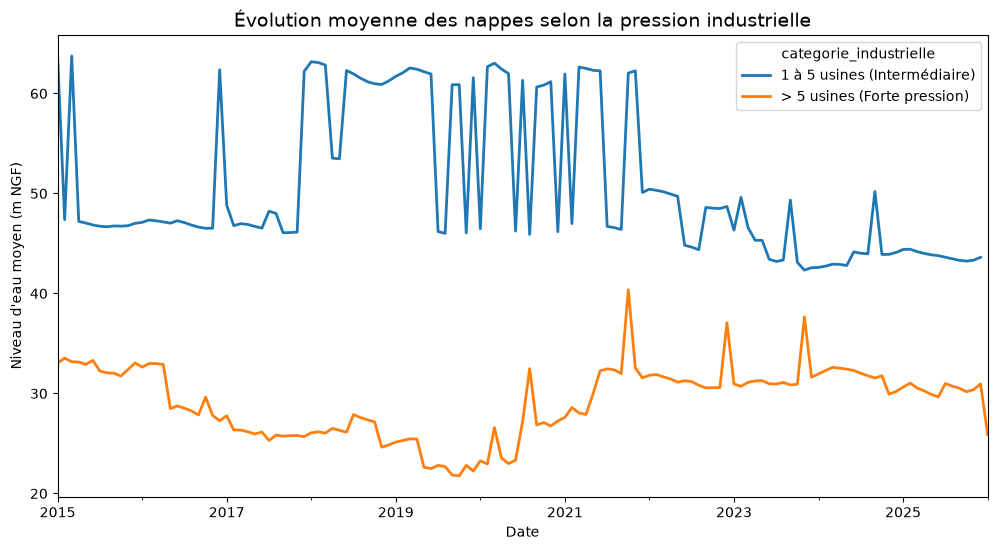

In [ ]:
def fig_evolution_par_pression():
    """Niveau moyen (en m NGF) des stations de chaque groupe de pression industrielle, mois par mois."""
    evolution_lisse.plot(figsize=(12, 6), linewidth=2)
    plt.title("Évolution moyenne des nappes selon la pression industrielle", fontsize=14)
    plt.ylabel("Niveau d'eau moyen (m NGF)")
    plt.xlabel("Date")
    plt.show()

if AFFICHER:
    fig_evolution_par_pression()

On observe que, en moyenne, les nappes qui ont plus de 5 usines à moins de 5 km ont un niveau inférieur d'environ 20 m.  
Nous n'avons pourtant pas établi de causalité : `niveau_nappe_eau` est une altitude (par rapport au niveau de la mer), donc cet écart reflète d'abord l'endroit où se trouvent les stations. 
Les sauts brusques des courbes viennent aussi de ce que l'ensemble des stations mesurées change d'un mois à l'autre.

Les nappes phréatiques sont affectées majoritairement par 3 choses :  
- l'altitude, la topographie et la géologie (partie 3) ;  
- la pluie (partie 4) ;  
- l'industrie (partie 5).

In [ ]:
#Marqueur : cette étape est faite, les notebooks qui en dépendent ne la relanceront pas dans ce noyau
ETAPE_02 = True